# Dedicated MX E4M3/A32 — resultaten van de vijfepochproef

Dit notebook analyseert **uitsluitend opgeslagen resultaten** van de dedicated E4M3-gewichtsproef: CNN-8/SVHN train-only, A32-activaties en een FP32-updatemaster. Er wordt geen training gestart en geen checkpoint geladen.

De grafieken tonen de **laatste gemeten epoch**, het **beste E4M3-checkpoint** en het vaste **epoch100-eindpunt zodra dat werkelijk beschikbaar is**. Bij deze pilot is de laatste epoch normaal 5. Ontbrekende eindaccuracies worden niet voorspeld. Synthetische controlegegevens worden bovenaan en in iedere figuurtitel herkenbaar gemarkeerd.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_e4m3_dedicated_pilot5\\20261022_184112_866638_mx_run')
SAVE_FIGURES = True  # Nieuwe analysemap; ruwe resultaten blijven behouden.


In [2]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:  # Ook analyse vanuit een gewone Python-omgeving blijft mogelijk.
    class Markdown(str):
        pass
    def display(value):
        print(value)

sys.path.insert(0, str(RUN_DIR.expanduser().resolve()))
import notebook_support as ns

run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **5**.

**Epoch100 niet uitgevoerd; geen eindresultaat.** Vijf epochs beoordelen techniek, eerste leergedrag en looptijd.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsformaat,MXFP8_E4M3
1,Activaties,A32
2,Updatemaster,float32
3,Model,"svhnq, expand=2"
4,Data,svhn; train-split=train; extra=False
5,Train / test,73257 / 26032
6,Groepsgrootte / schaal,32 / E8M0
7,Batch / seed,128 / 20261009
8,Afgeronde epochs,5
9,Beste checkpoint,first strict maximum of active-mode official-t...


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Checkpointselectie en vergelijking

**Beste checkpoint:** het eerste strikte maximum van de opgeslagen E4M3-testaccuracy. Een gelijke score vervangt het eerdere beste checkpoint niet. Alle hieronder vermelde scores komen uit dezelfde dedicated run. De selectiebron en checkpointnaam staan expliciet in de tabel; een ontbrekend selectiebestand wordt niet stilzwijgend als bevestigde selectie behandeld.

De officiële testset wordt volgens het bestaande protocol gebruikt voor selectie. De beste score is daarom **geen onafhankelijke testschatting na selectie**. Bij een volledige latere run blijft epoch100 het vaste hoofdvergelijkingspunt; de beste epoch wordt apart getoond.


,Controlepunt,Epoch,Testaccuracy [%],Correct / n,CE-loss,Selectiebron,Checkpoint
0,Laatste epoch,5,93.139213,24.246 / 26.032,0.235969,checkpoint_selection.json,last_checkpoint.pt
1,Beste E4M3-checkpoint,5,93.139213,24.246 / 26.032,0.235969,checkpoint_selection.json,best_checkpoint.pt
2,Vast eindpunt epoch100,100,NaN,—,NaN,niet uitgevoerd / niet beschikbaar,vast epochnummer; geen nieuwe selectie


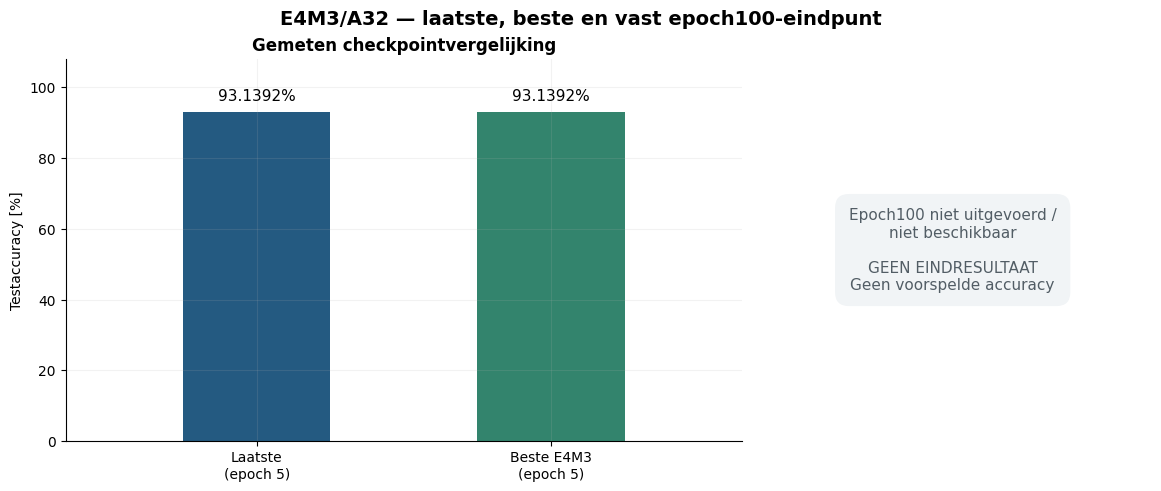

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'CE-loss': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Leercurves

Trainaccuracy en trainloss zijn tijdens de updates verzameld; testmetrics zijn na de epoch met bevroren evaluatiestaat gemeten. De figuur toont uitsluitend gemeten epochs.

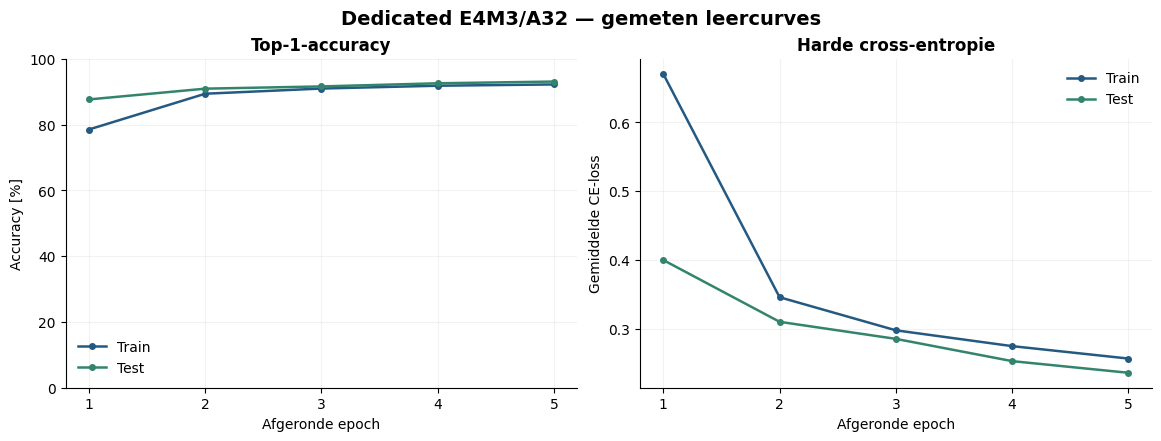

In [4]:
display(Markdown('## Leercurves\n\nTrainaccuracy en trainloss zijn tijdens de updates verzameld; testmetrics zijn na de epoch met bevroren evaluatiestaat gemeten. De figuur toont uitsluitend gemeten epochs.'))
figures['learning_curves'] = ns.plot_learning(run)
display(figures['learning_curves'])
plt.close(figures['learning_curves'])


## Looptijd en schatting voor een nieuwe training van 100 epochs

Warme epochs volgens het tijdsrapport: **[2, 3, 4, 5]**; mediaan: **25.1 s**. De schatting geldt voor een **nieuwe run van 100 epochs vanaf initialisatie**, niet voor het hervatten van deze pilot. De eerste gemeten epoch wordt apart geteld; het waargenomen minimum/maximum van de warme epochs levert alleen een scenario-bereik. Dit is geen statistisch betrouwbaarheidsinterval. Download, installatie, data-inladen en eindrapportage zijn niet inbegrepen. Vijf epochs meten geen langdurige thermische vertraging of LR-overgangen op epochs50/75/90. Er wordt **geen accuracy voor epoch100 voorspeld**.

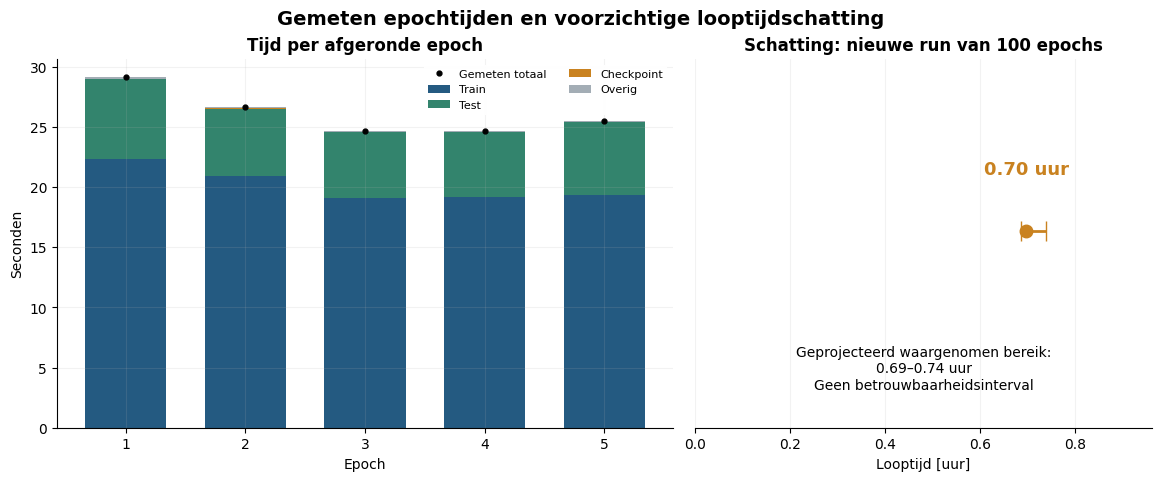

In [5]:
display(Markdown('## Looptijd en schatting voor een nieuwe training van 100 epochs'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

Toegewezen en gereserveerd geheugen zijn de opgeslagen pieken van de PyTorch CUDA-allocator. Dit is geen meting van alle GPU-processen en geen bewijs van compacte native MX-uitvoering. Ontbrekende metingen blijven ontbrekend.

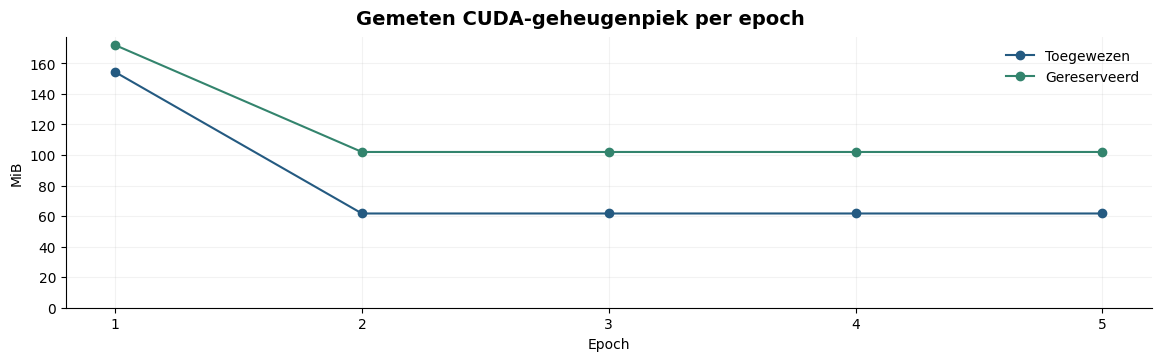

In [6]:
display(Markdown('## GPU-geheugen\n\nToegewezen en gereserveerd geheugen zijn de opgeslagen pieken van de PyTorch CUDA-allocator. Dit is geen meting van alle GPU-processen en geen bewijs van compacte native MX-uitvoering. Ontbrekende metingen blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [7]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabel rapporteert bestaande controles uit de run; het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates per epoch en doellaag'))
display(ns.weight_update_table(run))


## Opgeslagen technische controles

Deze tabel rapporteert bestaande controles uit de run; het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,Bronbestanden onveranderd,True
3,Ruwe datasetbestanden onveranderd,True
4,Optimizerupdates,2865
5,Selectie op officiële testset,True
6,Onafhankelijke testschatting,False


### Gewichtsupdates per epoch en doellaag

,epoch,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,layers.3,1728,1.167723,torch.float32,1630,4
1,1,layers.6,2304,1.360897,torch.float32,2185,30
2,1,layers.10,4608,2.003157,torch.float32,4399,32
3,1,layers.13,9216,2.843685,torch.float32,8936,29
4,1,layers.16,9216,2.984951,torch.float32,9007,9
5,1,layers.20,102400,11.041567,torch.float32,99338,742
6,2,layers.3,1728,0.518585,torch.float32,1480,1
7,2,layers.6,2304,0.649921,torch.float32,2049,15
8,2,layers.10,4608,1.000883,torch.float32,4093,20
9,2,layers.13,9216,1.515414,torch.float32,8430,31


## Betekenis van deze pilot

Vijf epochs dienen voor de technische werking, het eerste leergedrag en een looptijdmeting. Ze stellen de uiteindelijke accuracy, het gedrag na de LR-dalingen of de winst van exponenttruncatie nog niet vast. Deze dedicated proef bevat geen distillatie of truncatie; latere gezamenlijke en truncatieproeven krijgen eigen resultaten.

Een volledige training begint later opnieuw vanaf initialisatie. Dit notebook biedt daarvoor geen trainingsopdracht. Bij een onderbroken of mislukte run blijven eventueel beschikbare epochs zichtbaar, samen met de runstatus en meldingen bovenaan.

Met `SAVE_FIGURES = True` worden alleen de vier figuren en een analysemanifest naar een **nieuwe** map geschreven. Een volgende uitvoering maakt opnieuw een nieuwe map. Geen JSON, CSV, checkpoint of eerdere figuur wordt overschreven.


In [8]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')

print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [path.name for path in run.input_files]}))


Figuren opgeslagen in: C:\Users\renzo\master-thesis-mx\mx_runs\mx_e4m3_dedicated_pilot5\20261022_184112_866638_mx_run\analysis_20261022_184452_599951
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_e4m3_dedicated_pilot5\20261022_184112_866638_mx_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
